In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('D:\AI LABRATORY\Learning Notebooks\student_exam_scores.csv')

<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
C:\Users\aitza\AppData\Local\Temp\ipykernel_12964\1126992604.py:1: SyntaxWarning: invalid escape sequence '\A'
  df = pd.read_csv('D:\AI LABRATORY\Learning Notebooks\student_exam_scores.csv')


In [3]:
df

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3
...,...,...,...,...,...,...
195,S196,10.5,5.4,94.0,87,42.7
196,S197,7.1,6.1,85.1,92,40.4
197,S198,1.6,6.9,63.8,76,28.2
198,S199,12.0,7.3,50.5,58,42.0


In [5]:
df.drop(columns=['student_id'], inplace=True)

In [7]:
df.sample(5)

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
66,3.5,7.1,61.6,54,21.7
56,2.9,4.4,88.3,86,35.2
174,9.9,5.8,63.5,90,44.8
102,8.5,8.2,69.7,65,35.7
5,8.4,5.1,58.5,75,35.7


In [8]:
x = df.drop(columns=['exam_score'])

In [9]:
y = df['exam_score']

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
from sklearn.ensemble import RandomForestRegressor

In [11]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [13]:
model_1 = DecisionTreeRegressor()

In [14]:
model_1.fit(x_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [15]:
yhat = model_1.predict(x_test)

In [16]:
score = r2_score(y_test, yhat)

In [17]:
score

0.5348981818387379

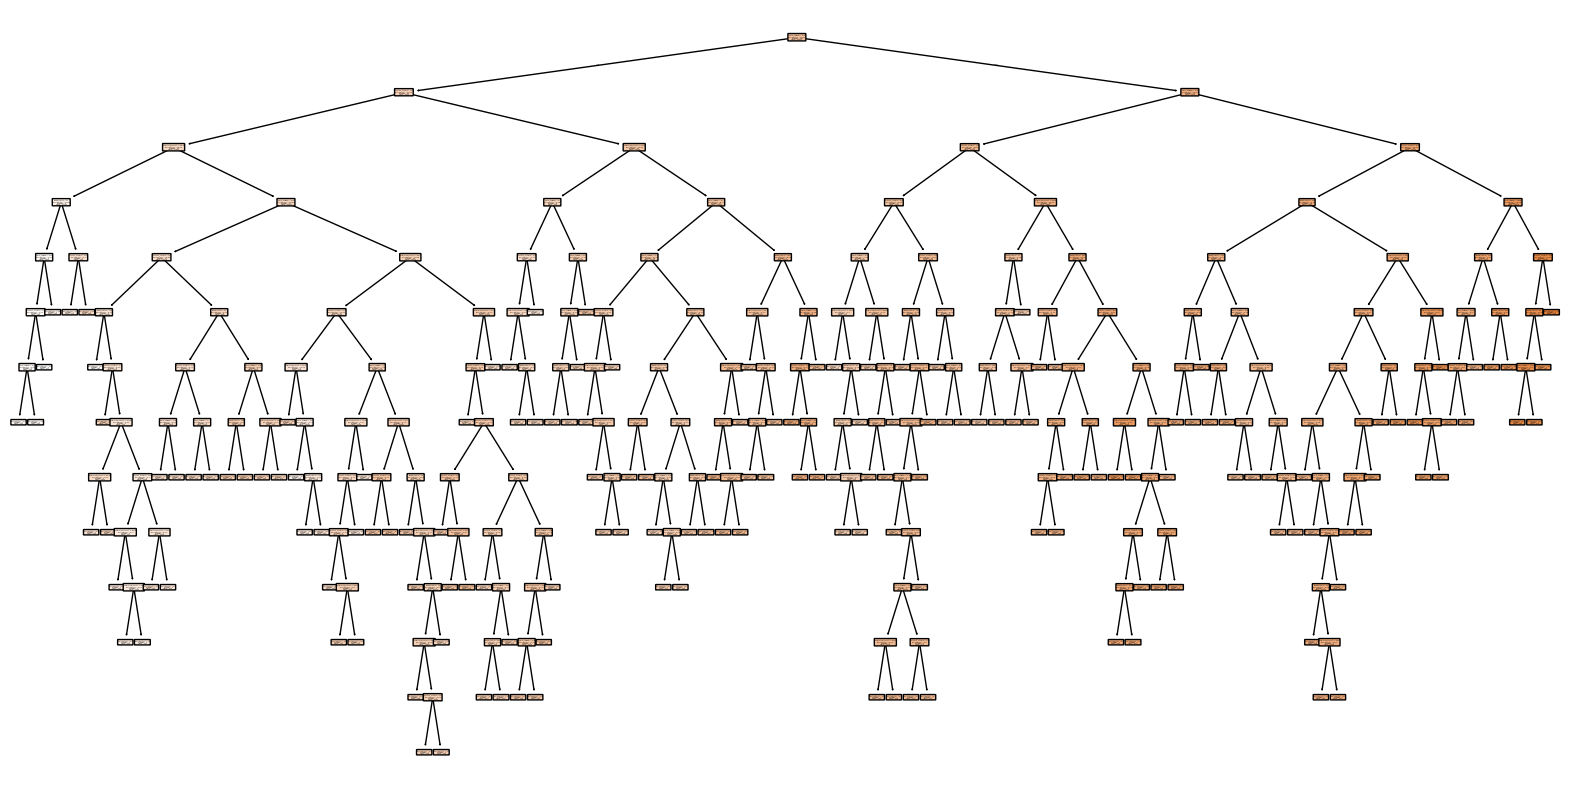

In [20]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

# Assuming model_1 is a DecisionTreeRegressor
plt.figure(figsize=(20,10))  # Make the figure large for readability
plot_tree(model_1, 
          feature_names=x_train.columns if hasattr(x_train, 'columns') else None, 
          filled=True, 
          rounded=True)
plt.show()


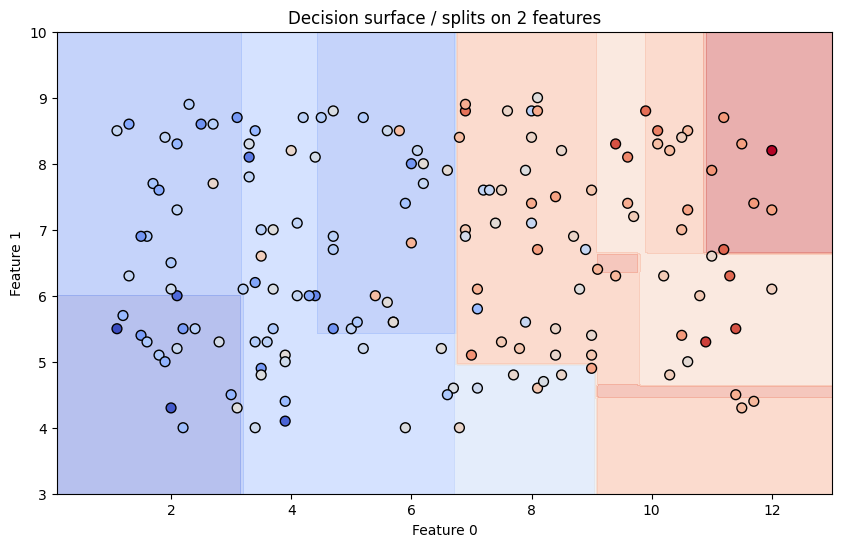

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Choose two features to plot
feat1, feat2 = 0, 1  # indices of features to visualize

X_plot = x_train.values
y = y_train.values

x_min, x_max = X_plot[:,feat1].min() - 1, X_plot[:,feat1].max() + 1
y_min, y_max = X_plot[:,feat2].min() - 1, X_plot[:,feat2].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Create full input with fixed values for other features
X_full = np.zeros((xx.ravel().shape[0], X_plot.shape[1]))
X_full[:, feat1] = xx.ravel()
X_full[:, feat2] = yy.ravel()

# Set other features to mean values
for i in range(X_plot.shape[1]):
    if i != feat1 and i != feat2:
        X_full[:, i] = X_plot[:, i].mean()

# Predict
Z = model_1.predict(X_full)
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(10,6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
plt.scatter(X_plot[:,feat1], X_plot[:,feat2], c=y, s=50, edgecolor='k', cmap=plt.cm.coolwarm)
plt.xlabel(f'Feature {feat1}')
plt.ylabel(f'Feature {feat2}')
plt.title('Decision surface / splits on 2 features')
plt.show()


In [32]:
model_2 = RandomForestRegressor(n_estimators=200, random_state=42, max_samples=0.8)  # Using 80% of data for each tree

In [33]:
model_2.fit(x_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [34]:
yhat_2 = model_2.predict(x_test)

In [35]:
score2 = r2_score(y_test, yhat_2)

In [36]:
score

0.5348981818387379

d:\Anaconda\envs\GenAI\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


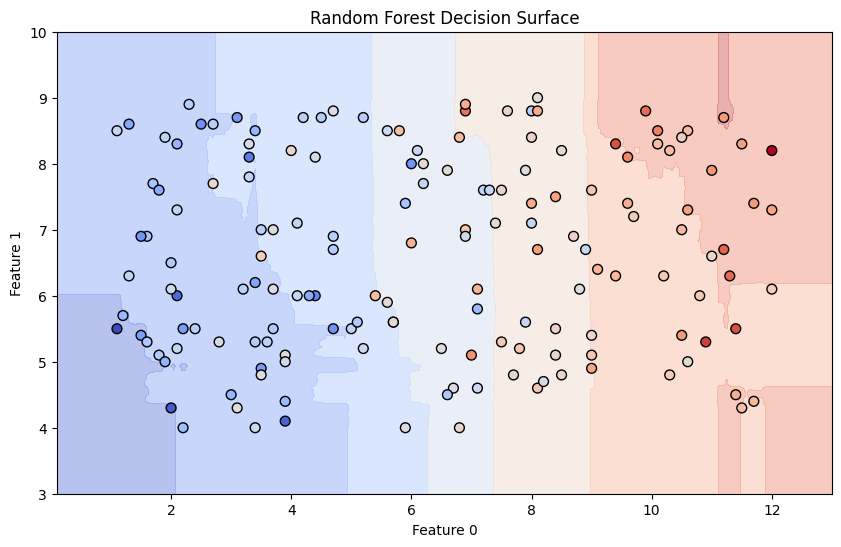

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# Assume model_2 is your RandomForestRegressor
model_2.fit(x_train, y_train)

# Choose two features to visualize
feat1, feat2 = 0, 1  # indices of features to plot
X_plot = x_train.values
y = y_train.values

# Create mesh grid
x_min, x_max = X_plot[:,feat1].min() - 1, X_plot[:,feat1].max() + 1
y_min, y_max = X_plot[:,feat2].min() - 1, X_plot[:,feat2].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Prepare full input (fill other features with mean)
X_full = np.zeros((xx.ravel().shape[0], X_plot.shape[1]))
X_full[:, feat1] = xx.ravel()
X_full[:, feat2] = yy.ravel()
for i in range(X_plot.shape[1]):
    if i != feat1 and i != feat2:
        X_full[:, i] = X_plot[:, i].mean()

# Predict over the grid
Z = model_2.predict(X_full)
Z = Z.reshape(xx.shape)

# Plot decision surface
plt.figure(figsize=(10,6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
plt.scatter(X_plot[:,feat1], X_plot[:,feat2], c=y, s=50, edgecolor='k', cmap=plt.cm.coolwarm)
plt.xlabel(f'Feature {feat1}')
plt.ylabel(f'Feature {feat2}')
plt.title('Random Forest Decision Surface')
plt.show()


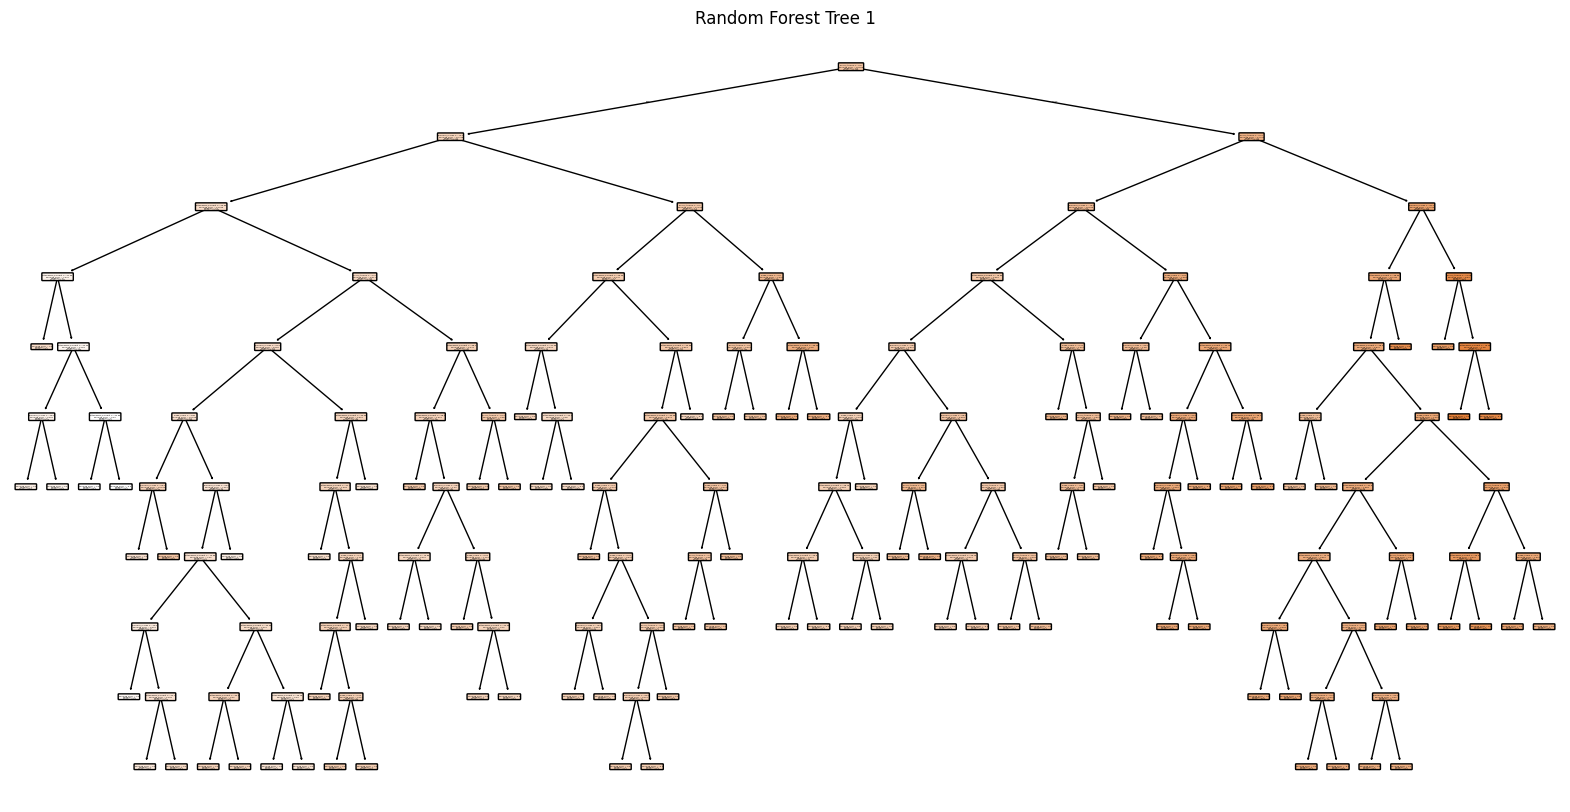

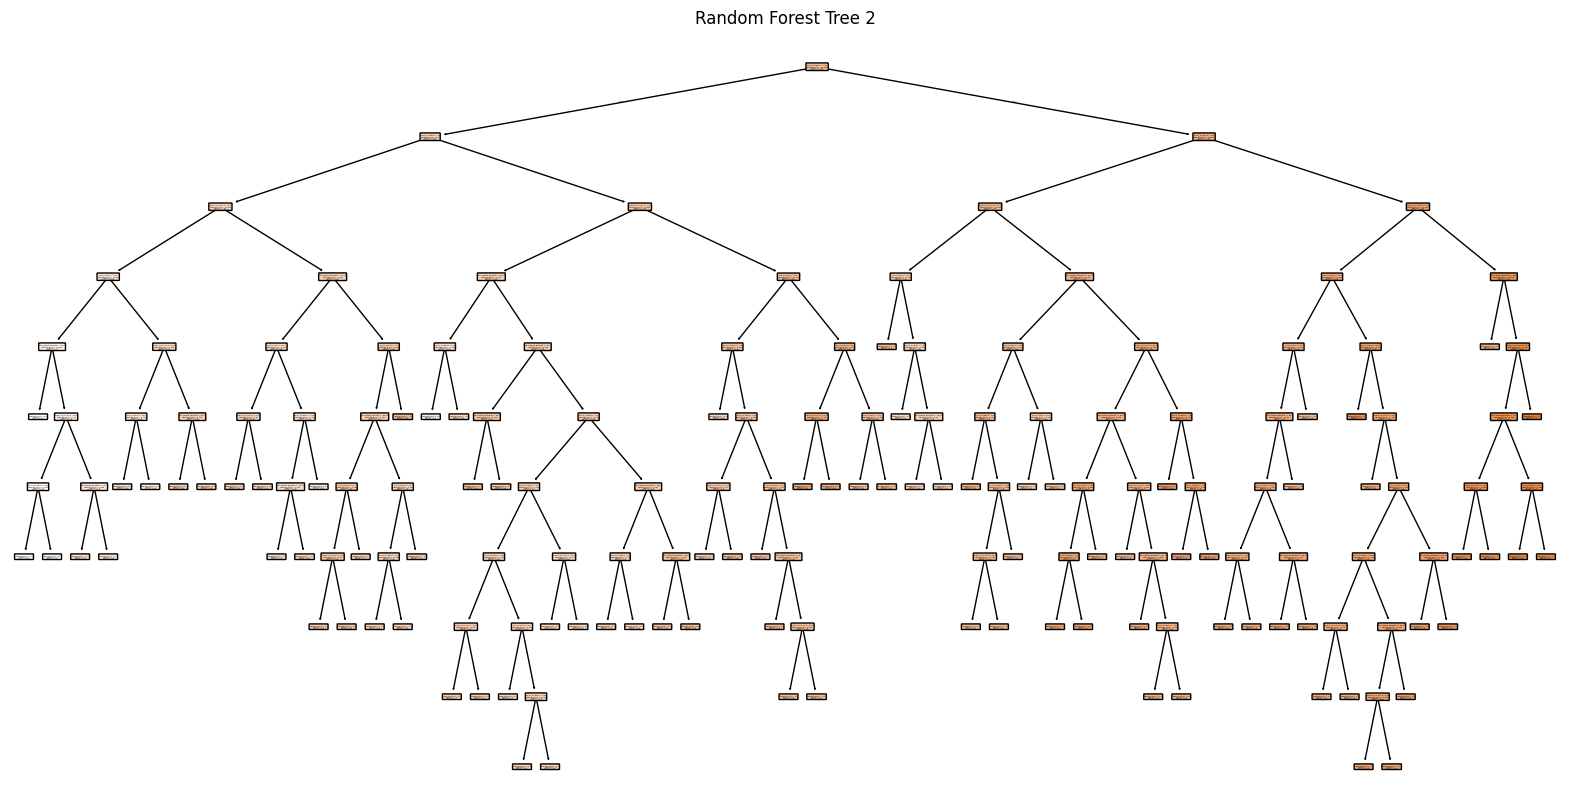

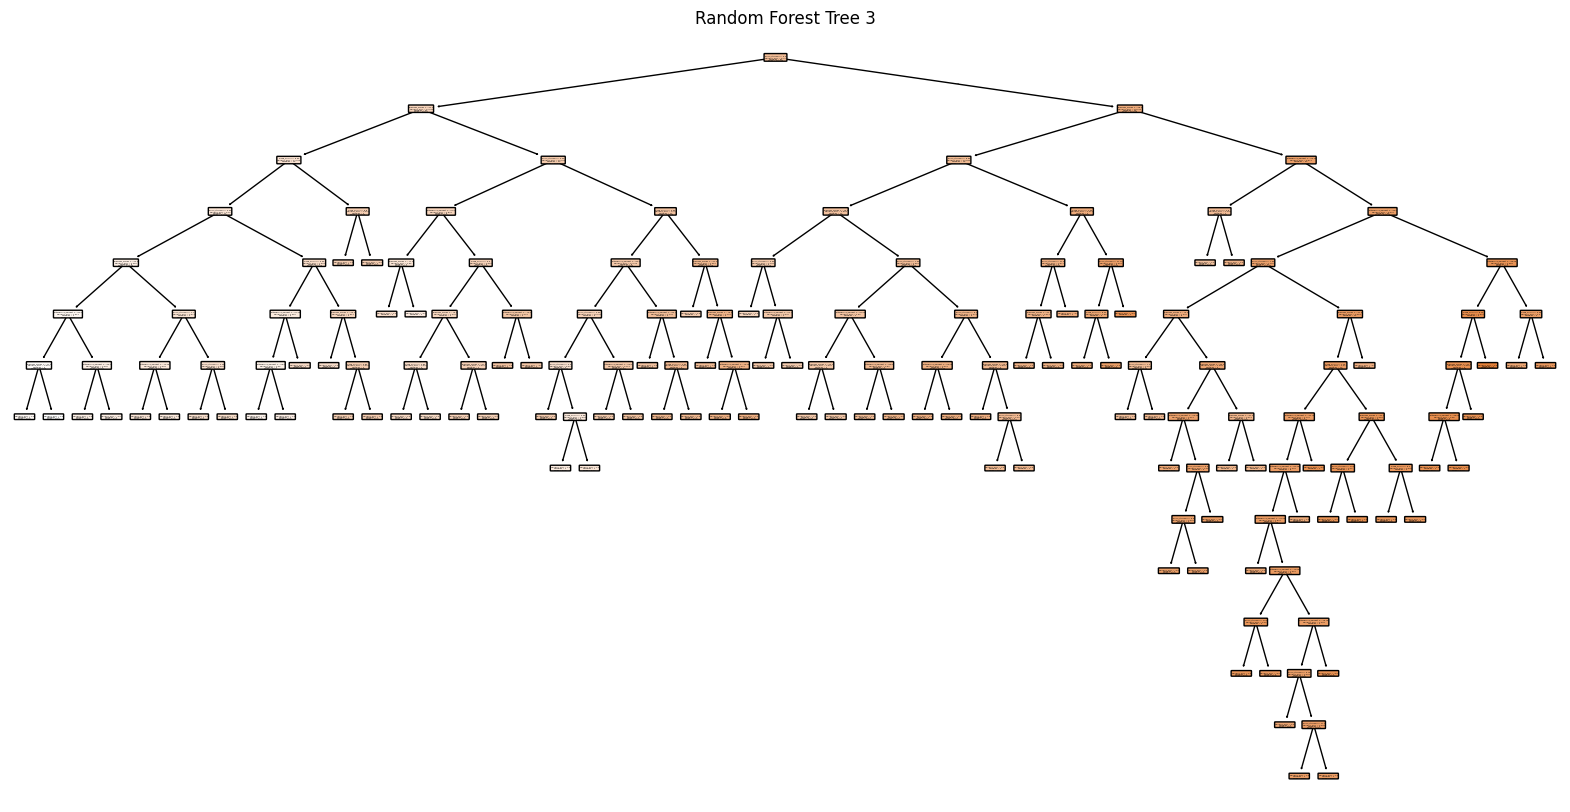

In [40]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Visualize the first 10 trees
for idx, tree in enumerate(model_2.estimators_[:3]):
    plt.figure(figsize=(20,10))
    plot_tree(tree, 
              feature_names=x_train.columns if hasattr(x_train, 'columns') else [f'X{i}' for i in range(x_train.shape[1])],
              filled=True,
              rounded=True)
    plt.title(f'Random Forest Tree {idx+1}')
    plt.show()


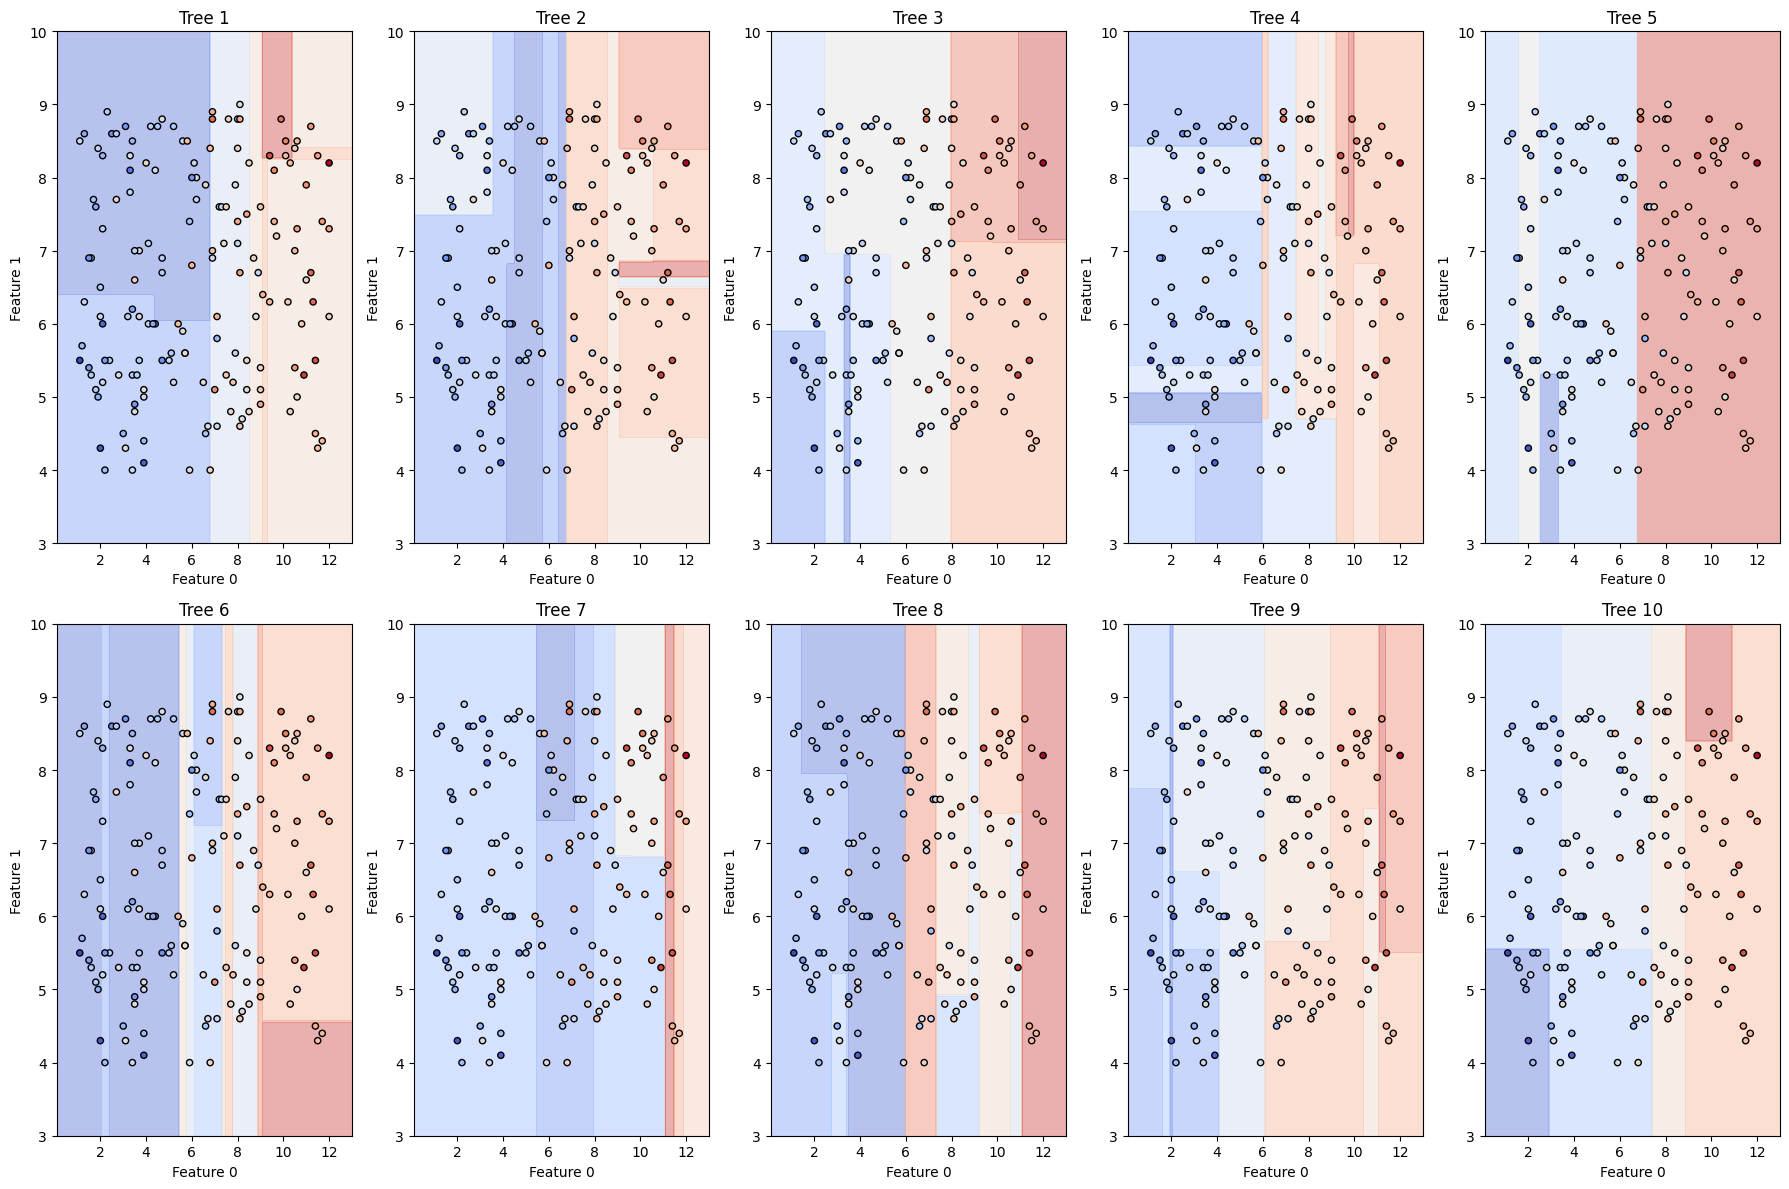

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# Fit the Random Forest
model_2.fit(x_train, y_train)

# Choose two features to plot
feat1, feat2 = 0, 1
X_plot = x_train.values
y = y_train.values

# Create a meshgrid for the plot
x_min, x_max = X_plot[:,feat1].min() - 1, X_plot[:,feat1].max() + 1
y_min, y_max = X_plot[:,feat2].min() - 1, X_plot[:,feat2].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Fix other features to mean values
X_full = np.zeros((xx.ravel().shape[0], X_plot.shape[1]))
X_full[:, feat1] = xx.ravel()
X_full[:, feat2] = yy.ravel()
for i in range(X_plot.shape[1]):
    if i != feat1 and i != feat2:
        X_full[:, i] = X_plot[:, i].mean()

# Plot individual trees
plt.figure(figsize=(18, 12))

for idx, tree in enumerate(model_2.estimators_[:10]):  # first 10 trees
    Z = tree.predict(X_full).reshape(xx.shape)
    
    plt.subplot(2, 5, idx+1)
    plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
    plt.scatter(X_plot[:,feat1], X_plot[:,feat2], c=y, s=20, edgecolor='k', cmap=plt.cm.coolwarm)
    plt.title(f'Tree {idx+1}')
    plt.xlabel(f'Feature {feat1}')
    plt.ylabel(f'Feature {feat2}')

plt.tight_layout()
plt.show()


In [41]:
model_3 = DecisionTreeRegressor(max_depth=3)  # Limiting depth to 3 for interpretability

In [43]:
model_3.fit(x_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [44]:
yhat_3 = model_3.predict(x_test)

In [45]:
score_3 = r2_score(y_test, yhat_3)

In [46]:
score_3

0.6192672587201191

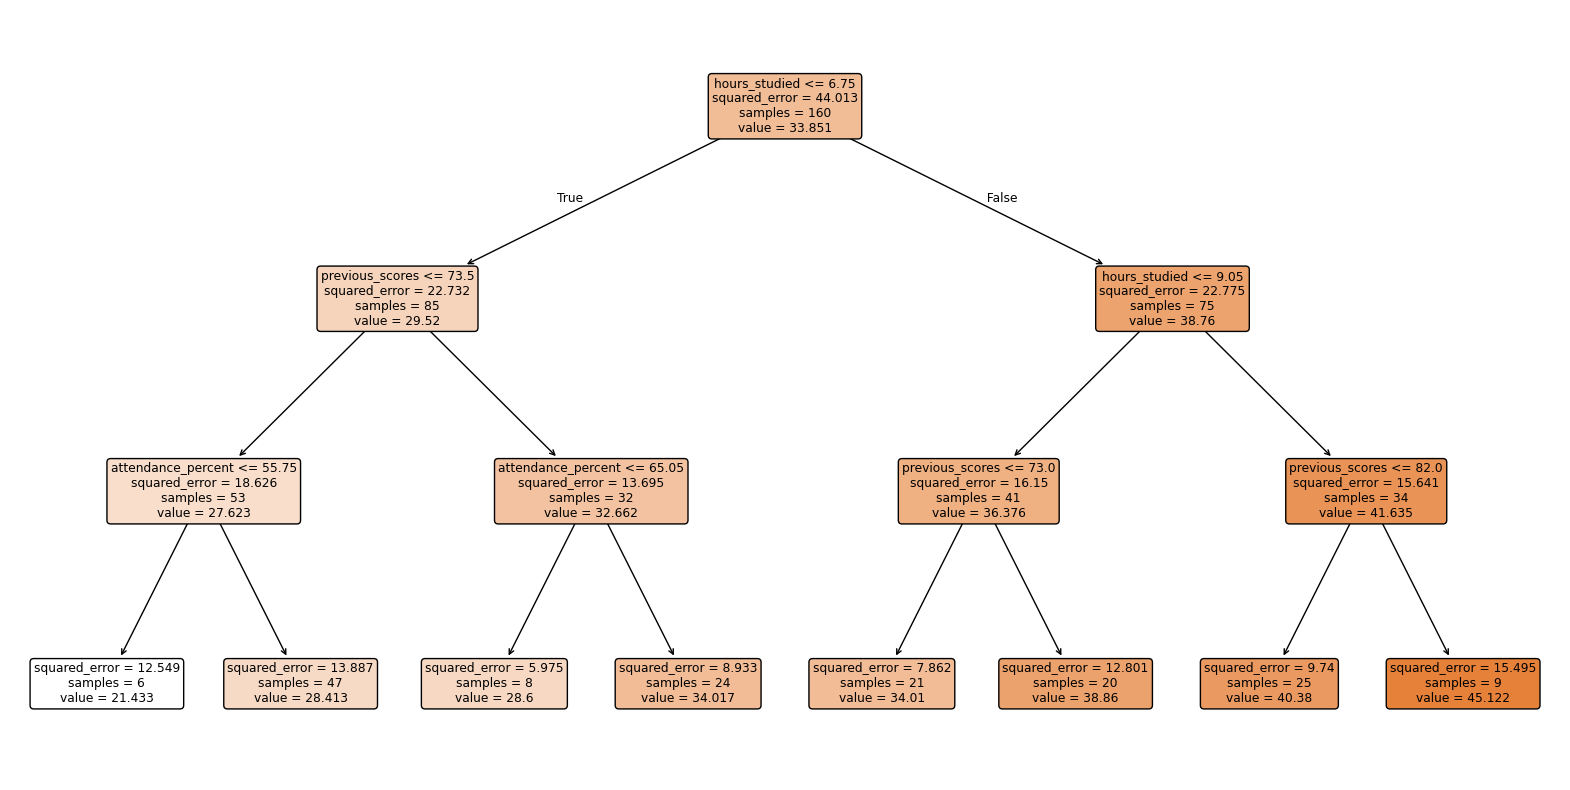

In [47]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

# Assuming model_1 is a DecisionTreeRegressor
plt.figure(figsize=(20,10))  # Make the figure large for readability
plot_tree(model_3, 
          feature_names=x_train.columns if hasattr(x_train, 'columns') else None, 
          filled=True, 
          rounded=True)
plt.show()


d:\Anaconda\envs\GenAI\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


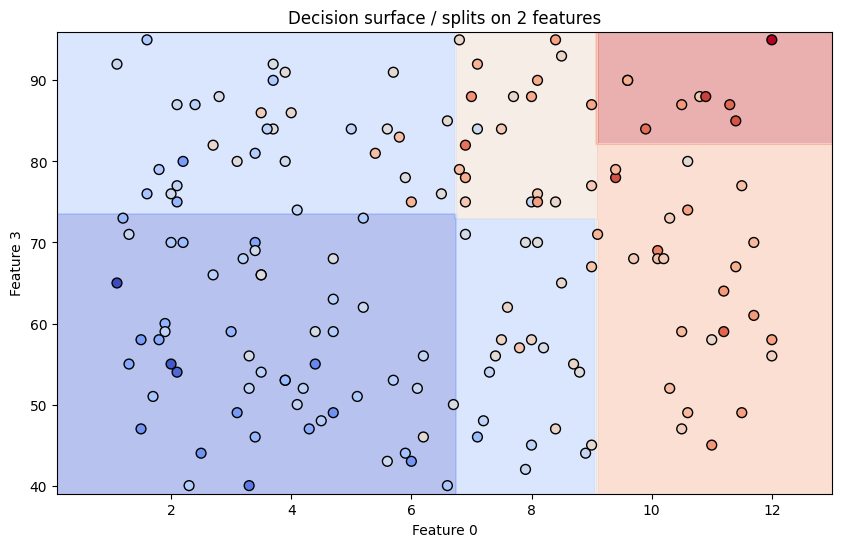

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Choose two features to plot
feat1, feat2 = 0, 3  # indices of features to visualize

X_plot = x_train.values
y = y_train.values

x_min, x_max = X_plot[:,feat1].min() - 1, X_plot[:,feat1].max() + 1
y_min, y_max = X_plot[:,feat2].min() - 1, X_plot[:,feat2].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Create full input with fixed values for other features
X_full = np.zeros((xx.ravel().shape[0], X_plot.shape[1]))
X_full[:, feat1] = xx.ravel()
X_full[:, feat2] = yy.ravel()

# Set other features to mean values
for i in range(X_plot.shape[1]):
    if i != feat1 and i != feat2:
        X_full[:, i] = X_plot[:, i].mean()

# Predict
Z = model_3.predict(X_full)
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(10,6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
plt.scatter(X_plot[:,feat1], X_plot[:,feat2], c=y, s=50, edgecolor='k', cmap=plt.cm.coolwarm)
plt.xlabel(f'Feature {feat1}')
plt.ylabel(f'Feature {feat2}')
plt.title('Decision surface / splits on 2 features')
plt.show()


In [56]:
model_4 = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=3)
model_4.fit(x_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [57]:
yhat_4 = model_4.predict(x_test)

In [60]:
score_4 = r2_score(y_test, yhat_4)

In [61]:
score_4

0.7525294029333719

d:\Anaconda\envs\GenAI\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


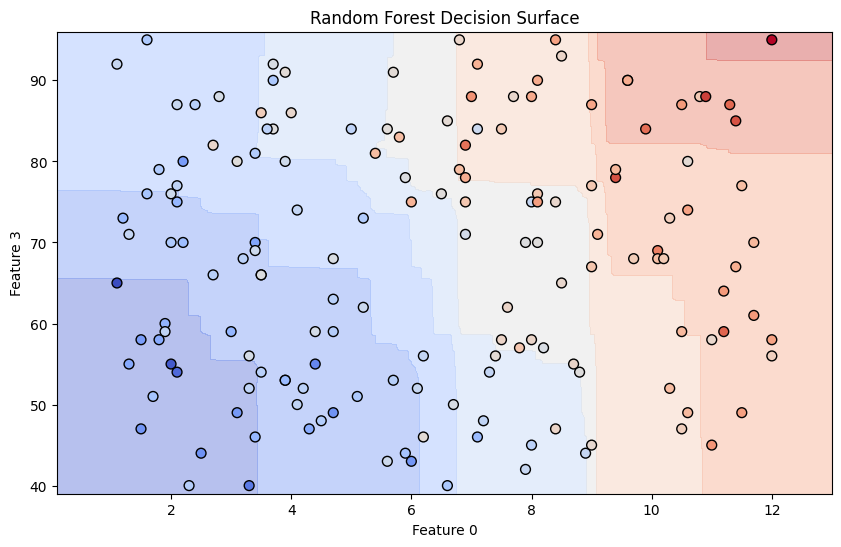

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# Assume model_2 is your RandomForestRegressor
model_4.fit(x_train, y_train)

# Choose two features to visualize
feat1, feat2 = 0, 3  # indices of features to plot
X_plot = x_train.values
y = y_train.values

# Create mesh grid
x_min, x_max = X_plot[:,feat1].min() - 1, X_plot[:,feat1].max() + 1
y_min, y_max = X_plot[:,feat2].min() - 1, X_plot[:,feat2].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Prepare full input (fill other features with mean)
X_full = np.zeros((xx.ravel().shape[0], X_plot.shape[1]))
X_full[:, feat1] = xx.ravel()
X_full[:, feat2] = yy.ravel()
for i in range(X_plot.shape[1]):
    if i != feat1 and i != feat2:
        X_full[:, i] = X_plot[:, i].mean()

# Predict over the grid
Z = model_4.predict(X_full)
Z = Z.reshape(xx.shape)

# Plot decision surface
plt.figure(figsize=(10,6))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.coolwarm)
plt.scatter(X_plot[:,feat1], X_plot[:,feat2], c=y, s=50, edgecolor='k', cmap=plt.cm.coolwarm)
plt.xlabel(f'Feature {feat1}')
plt.ylabel(f'Feature {feat2}')
plt.title('Random Forest Decision Surface')
plt.show()


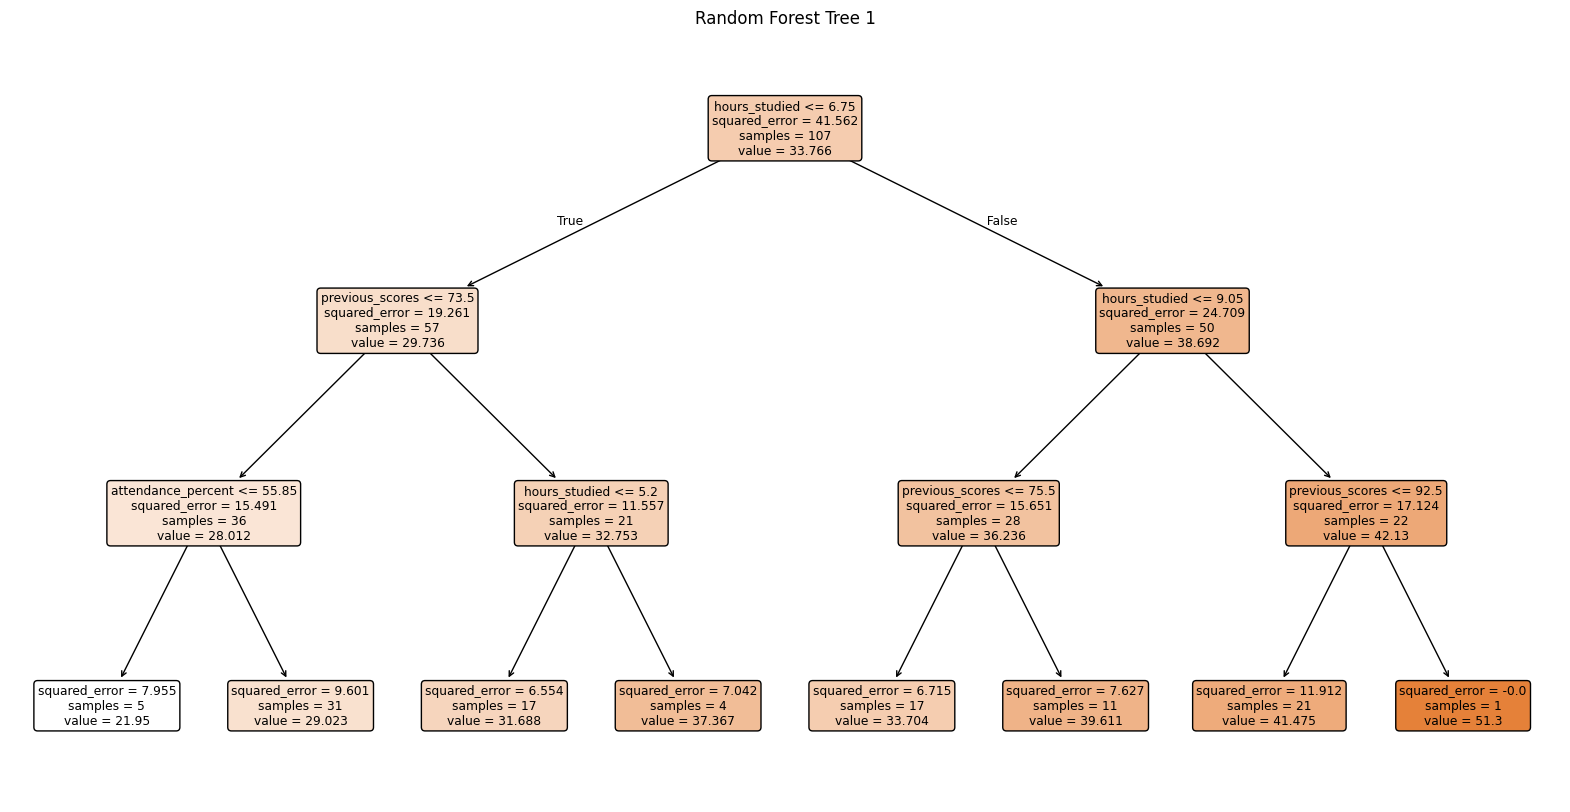

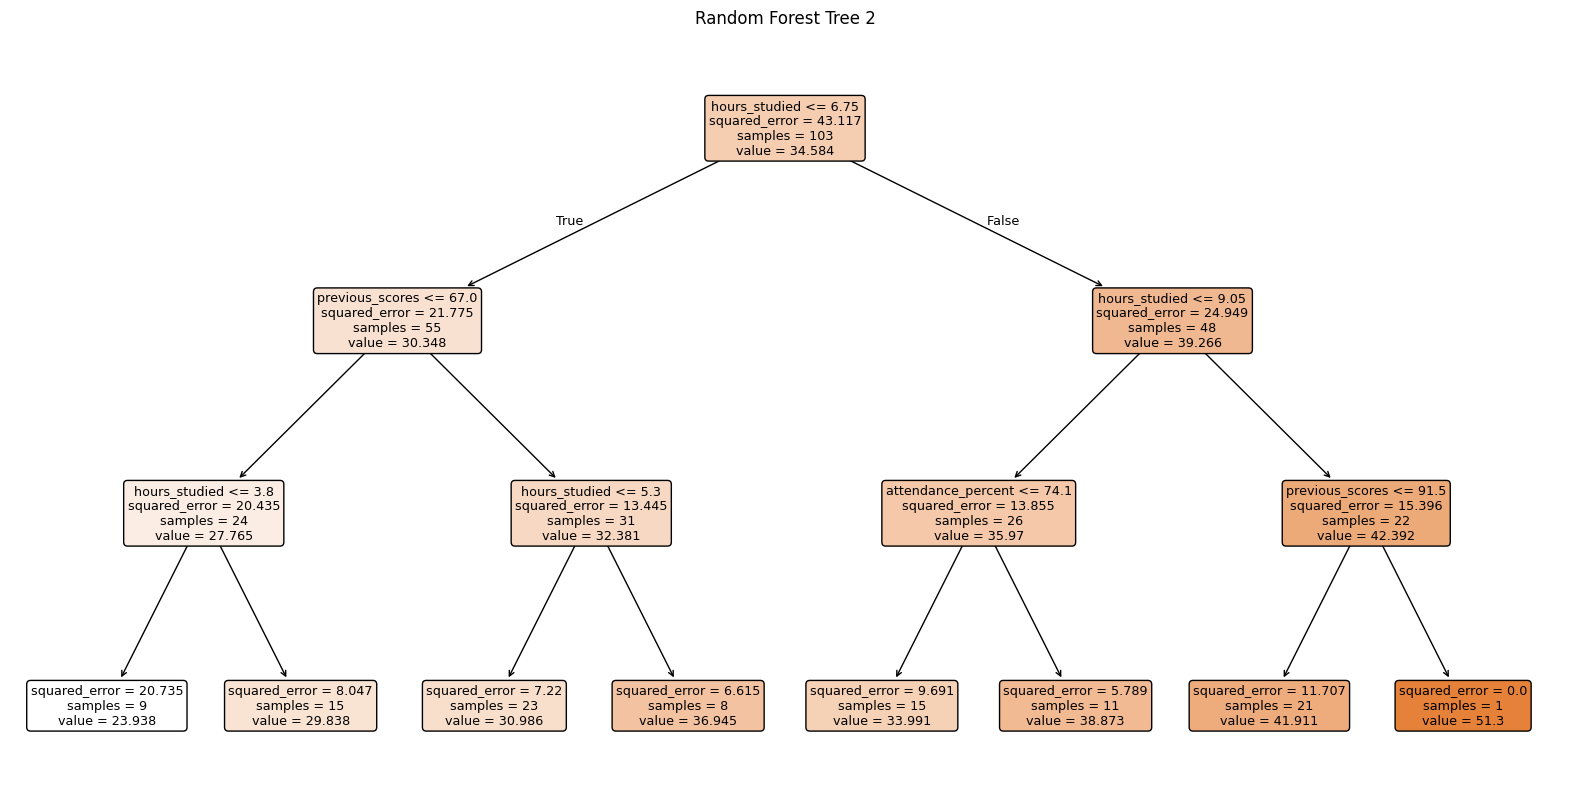

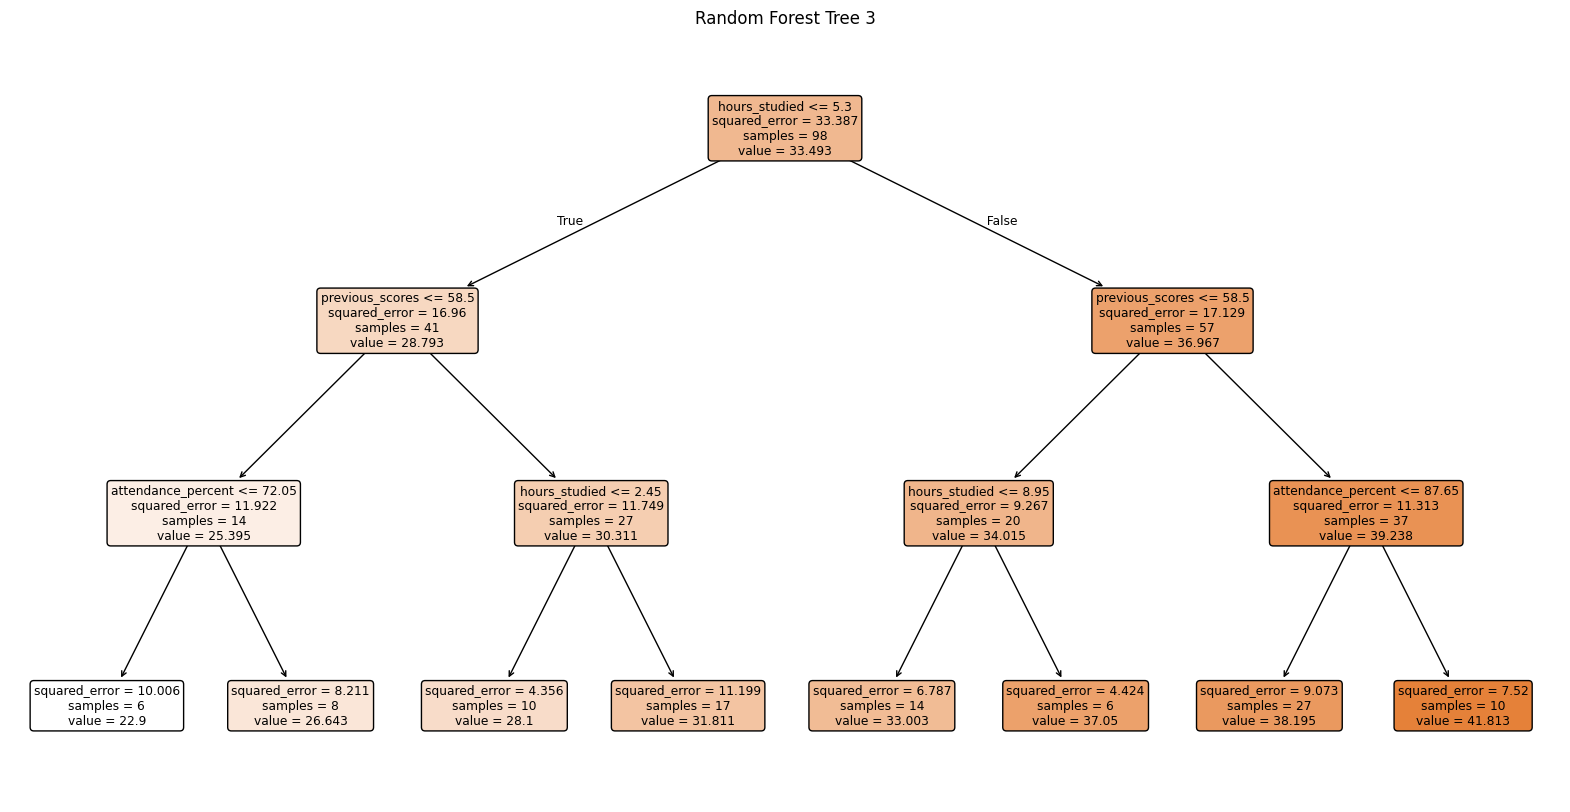

In [63]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Visualize the first 10 trees
for idx, tree in enumerate(model_4.estimators_[:3]):
    plt.figure(figsize=(20,10))
    plot_tree(tree, 
              feature_names=x_train.columns if hasattr(x_train, 'columns') else [f'X{i}' for i in range(x_train.shape[1])],
              filled=True,
              rounded=True)
    plt.title(f'Random Forest Tree {idx+1}')
    plt.show()
